In [ ]:
# Google Colab : télécharger les données de cette séance / download this session's data
import os, urllib.request
BASE = "https://raw.githubusercontent.com/Marzoug-Nabil/Nabil/main/academic/teaching/fsci6222/materials/s06/"
for f in ['consommation_energie.csv', 'maisons.csv']:
    os.makedirs('data', exist_ok=True)
    for dst in (f, os.path.join('data', f)):
        if not os.path.exists(dst):
            urllib.request.urlretrieve(BASE + f, dst)


# FSCI 6222 -- Analyse de donnees
# Complement seance 6 : Arbres et Random Forest face a la regression lineaire
## Notebook de demonstration

Universite de Moncton -- Faculte des sciences -- Ete 2026

---

En seance 6, nous avons construit une regression lineaire qui predit le prix d'une maison avec un R2 d'environ 0,92. **Peut-on faire mieux avec des modeles plus sophistiques ?**

Ce notebook compare la regression lineaire vue en cours a trois modeles plus complexes -- arbre de decision, foret aleatoire, gradient boosting -- sur le **meme dataset** `maisons.csv`. La conclusion va peut-etre vous surprendre : sur ces donnees-la, la regression lineaire **reste imbattable**.

**Pourquoi ce message est important ?** Parce qu'en pratique, beaucoup d'analystes sautent directement vers les modeles les plus complexes en pensant qu'ils sont forcement meilleurs. Ce notebook montre qu'un modele complexe n'apporte rien quand la **relation est deja lineaire**. La complexite ne se justifie que quand les donnees presentent des non-linearites.


## 1. Preparation


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

sns.set_style('whitegrid')
print('Environnement pret.')

Environnement pret.


In [14]:
df = pd.read_csv('maisons.csv')
print('Dimensions :', df.shape)
df.head()

Dimensions : (200, 6)


,id_maison,prix,superficie_m2,nb_chambres,age_maison,distance_centre_km
0,1,457.1,162,4,5,1.9
1,2,401.7,134,3,11,0.5
2,3,406.2,169,5,17,2.4
3,4,566.4,209,5,18,7.2
4,5,356.7,129,2,13,0.5


## 2. Diagnostic : la relation est-elle lineaire ?

Avant tout choix de modele, on regarde les nuages de points. Si les relations sont des droites, un modele lineaire suffira.


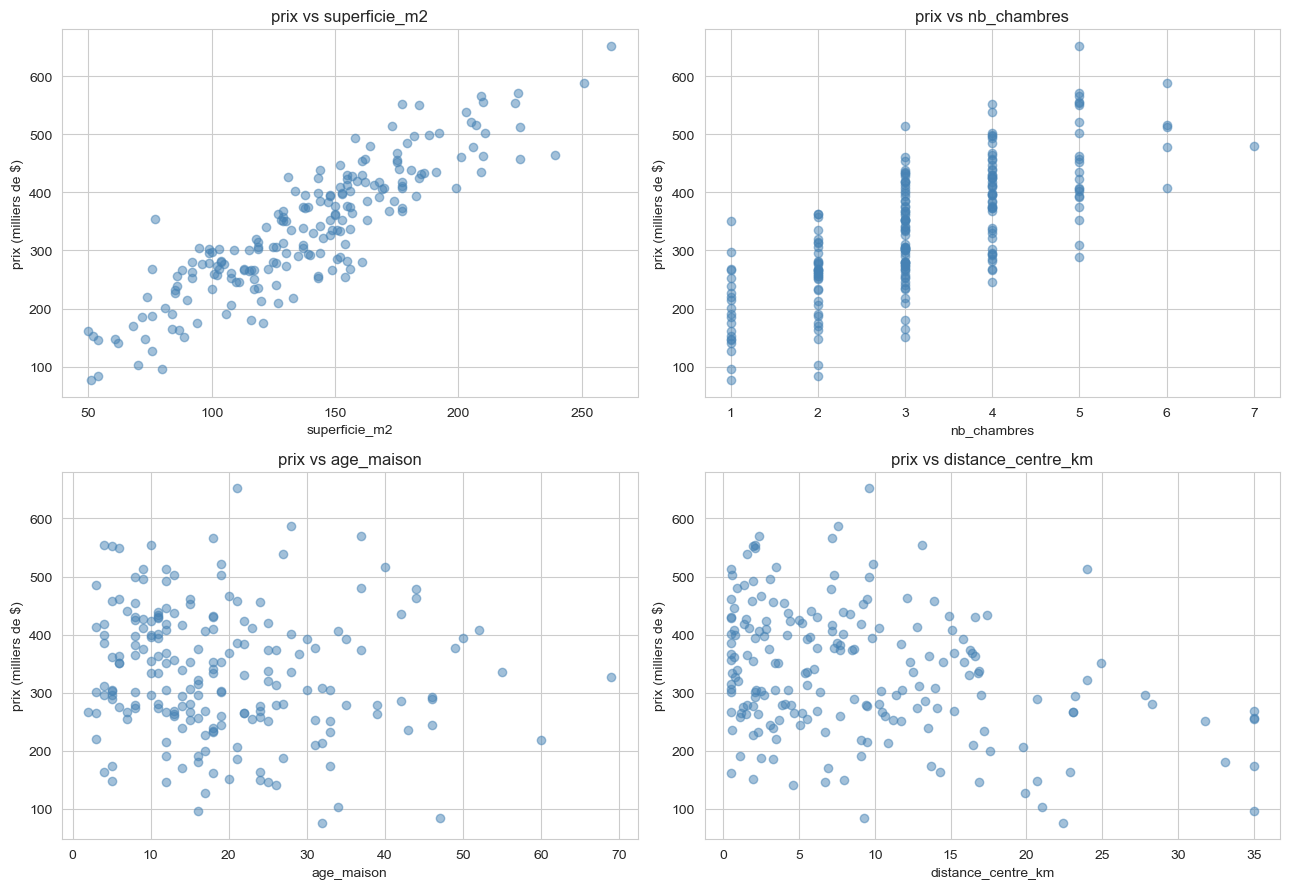

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
variables = ['superficie_m2', 'nb_chambres', 'age_maison', 'distance_centre_km']

for ax, var in zip(axes.flat, variables):
    ax.scatter(df[var], df['prix'], alpha=0.5, color='steelblue')
    ax.set_xlabel(var)
    ax.set_ylabel('prix (milliers de $)')
    ax.set_title(f'prix vs {var}')

plt.tight_layout()
plt.show()

**Diagnostic visuel.** Toutes les relations sont **approximativement lineaires** :

- la superficie et le nombre de chambres montrent une croissance lineaire claire du prix ;
- l'age et la distance au centre montrent une tendance lineaire descendante, plus faible.

Aucune relation en U, en cloche, ou en courbe. **Un modele lineaire devrait deja bien faire le travail.**


## 3. Preparer les donnees


In [16]:
cols = ['superficie_m2', 'nb_chambres', 'age_maison', 'distance_centre_km']
X = df[cols]
y = df['prix']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(f'Entrainement : {X_train.shape[0]} maisons')
print(f'Test         : {X_test.shape[0]} maisons')

Entrainement : 160 maisons
Test         : 40 maisons


## 4. La regression lineaire : notre baseline

On reprend la regression lineaire multiple de la seance 6.


In [17]:
lin = LinearRegression()
lin.fit(X_train, y_train)

r2_lin = lin.score(X_test, y_test)
rmse_lin = np.sqrt(mean_squared_error(y_test, lin.predict(X_test)))

print(f'Regression lineaire :')
print(f'  R2 test   = {r2_lin:.4f}')
print(f'  RMSE test = {rmse_lin:.2f} milliers de $')

Regression lineaire :
  R2 test   = 0.9017
  RMSE test = 29.45 milliers de $


**Resultat.** R2 d'environ 0,90, RMSE d'environ 29. Le modele explique 90 % de la variance du prix. C'est deja excellent. **Question : peut-on faire mieux avec des modeles plus complexes ?**


## 5. L'arbre de decision : le piege du surapprentissage

On essaie d'abord un arbre de decision **sans aucune limite de profondeur**. Par defaut, scikit-learn laisse l'arbre grandir jusqu'a memoriser chaque exemple.


In [18]:
arbre_naif = DecisionTreeRegressor(random_state=42)
arbre_naif.fit(X_train, y_train)

r2_train_naif = arbre_naif.score(X_train, y_train)
r2_test_naif = arbre_naif.score(X_test, y_test)
rmse_test_naif = np.sqrt(mean_squared_error(y_test, arbre_naif.predict(X_test)))

print(f'Arbre sans limite :')
print(f'  R2 entrainement = {r2_train_naif:.4f}')
print(f'  R2 test         = {r2_test_naif:.4f}')
print(f'  RMSE test       = {rmse_test_naif:.2f}')
print(f'  Profondeur      = {arbre_naif.get_depth()}')

Arbre sans limite :
  R2 entrainement = 1.0000
  R2 test         = 0.5959
  RMSE test       = 59.72
  Profondeur      = 14


**Diagnostic.** Le R2 d'entrainement est de **1,00** : l'arbre predit parfaitement les donnees vues. Mais le R2 de test chute autour de **0,60**. C'est l'illustration parfaite du **surapprentissage** : l'arbre a memorise les exemples d'entrainement mais ne sait pas generaliser.

Pour eviter ca, on **limite la profondeur**.


In [19]:
arbre = DecisionTreeRegressor(max_depth=5, random_state=42)
arbre.fit(X_train, y_train)

r2_arb = arbre.score(X_test, y_test)
rmse_arb = np.sqrt(mean_squared_error(y_test, arbre.predict(X_test)))

print(f'Arbre limite a profondeur 5 :')
print(f'  R2 test   = {r2_arb:.4f}')
print(f'  RMSE test = {rmse_arb:.2f}')
print(f'  (regression lineaire : R2 = {r2_lin:.4f})')

Arbre limite a profondeur 5 :
  R2 test   = 0.7473
  RMSE test = 47.22
  (regression lineaire : R2 = 0.9017)


**Resultat.** Meme limite, l'arbre n'arrive pas a battre la regression lineaire. **Pourquoi ?** Parce que l'arbre fonctionne par decoupage en zones et prediction par moyenne -- ce qui produit naturellement des predictions **en escalier**. Or les vraies relations du dataset sont des **droites continues**, pas des escaliers.


### Visualiser : prediction en escalier vs prediction lineaire

Pour comprendre pourquoi l'arbre echoue, on isole la variable la plus correlee au prix (la superficie) et on trace ce que predit chaque modele.


~/miniconda3/envs/research/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
~/miniconda3/envs/research/lib/python3.11/site-packages/sklearn/utils/validation.py:2691: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


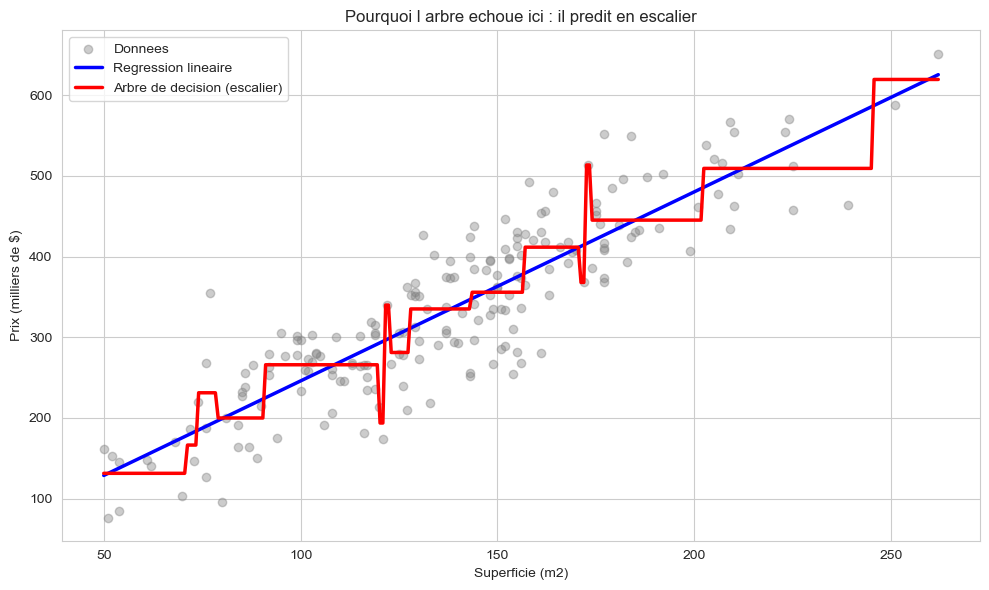

In [20]:
# On entraine deux modeles tres simples sur la seule variable superficie
X_super = df[['superficie_m2']]
y_pr = df['prix']

lin_simple = LinearRegression().fit(X_super, y_pr)
arbre_simple = DecisionTreeRegressor(max_depth=4, random_state=42).fit(X_super, y_pr)

# Grille pour tracer
grille = np.linspace(df['superficie_m2'].min(), df['superficie_m2'].max(), 300).reshape(-1, 1)

plt.figure(figsize=(10, 6))
plt.scatter(df['superficie_m2'], df['prix'], alpha=0.4, color='gray', label='Donnees')
plt.plot(grille, lin_simple.predict(grille), 'b-', linewidth=2.5,
         label='Regression lineaire')
plt.plot(grille, arbre_simple.predict(grille), 'r-', linewidth=2.5,
         label='Arbre de decision (escalier)')
plt.xlabel('Superficie (m2)')
plt.ylabel('Prix (milliers de $)')
plt.title('Pourquoi l arbre echoue ici : il predit en escalier')
plt.legend()
plt.tight_layout()
plt.show()

**Lecture.** La droite bleue (regression lineaire) passe au milieu du nuage en suivant naturellement la tendance. L'arbre rouge **decoupe** la superficie en zones et predit une **valeur constante** dans chaque zone -- d'ou la forme en escalier. Sur une vraie relation lineaire, l'escalier est toujours moins precis qu'une droite.


## 6. La foret aleatoire : meme idee, en mieux ?

Le Random Forest combine 200 arbres differents et moyenne leurs predictions. Cette moyenne lisse les escaliers et reduit le surapprentissage.


In [21]:
foret = RandomForestRegressor(n_estimators=200, random_state=42)
foret.fit(X_train, y_train)

r2_rf = foret.score(X_test, y_test)
rmse_rf = np.sqrt(mean_squared_error(y_test, foret.predict(X_test)))

print(f'Random Forest (200 arbres) :')
print(f'  R2 test   = {r2_rf:.4f}')
print(f'  RMSE test = {rmse_rf:.2f}')
print(f'  (regression lineaire : R2 = {r2_lin:.4f})')

Random Forest (200 arbres) :
  R2 test   = 0.8283
  RMSE test = 38.93
  (regression lineaire : R2 = 0.9017)


**Resultat.** La foret fait nettement mieux que l'arbre seul (R2 passe de 0,60 a environ 0,83), mais elle **reste en dessous** de la regression lineaire (0,90). Moyenner des escaliers donne une fonction plus lisse, mais ca reste une approximation par paliers d'une vraie droite.


## 7. Le Gradient Boosting : le modele le plus complexe

On pousse jusqu'au bout : Gradient Boosting construit les arbres en sequence, chacun corrigeant les erreurs du precedent. C'est souvent le modele le plus performant sur des donnees tabulaires.


In [22]:
gb = GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                max_depth=3, random_state=42)
gb.fit(X_train, y_train)

r2_gb = gb.score(X_test, y_test)
rmse_gb = np.sqrt(mean_squared_error(y_test, gb.predict(X_test)))

print(f'Gradient Boosting :')
print(f'  R2 test   = {r2_gb:.4f}')
print(f'  RMSE test = {rmse_gb:.2f}')
print(f'  (regression lineaire : R2 = {r2_lin:.4f})')

Gradient Boosting :
  R2 test   = 0.8311
  RMSE test = 38.61
  (regression lineaire : R2 = 0.9017)


**Resultat.** Le Gradient Boosting fait mieux que la foret aleatoire mais **reste en dessous** de la regression lineaire. Meme avec 200 arbres construits en sequence, on n'arrive pas a battre une droite ajustee correctement.


## 8. Comparaison finale


In [23]:
modeles = {
    'Regression lineaire': lin,
    'Arbre (profondeur 5)': arbre,
    'Random Forest (200 arbres)': foret,
    'Gradient Boosting': gb
}

resultats = []
for nom, m in modeles.items():
    r2 = m.score(X_test, y_test)
    rmse = np.sqrt(mean_squared_error(y_test, m.predict(X_test)))
    resultats.append({'Modele': nom, 'R2 test': r2, 'RMSE test': rmse})

comparaison = pd.DataFrame(resultats).sort_values('R2 test', ascending=False)
print(comparaison.to_string(index=False))

                    Modele  R2 test  RMSE test
       Regression lineaire 0.901750  29.446681
         Gradient Boosting 0.831069  38.612237
Random Forest (200 arbres) 0.828280  38.929603
      Arbre (profondeur 5) 0.747315  47.223631


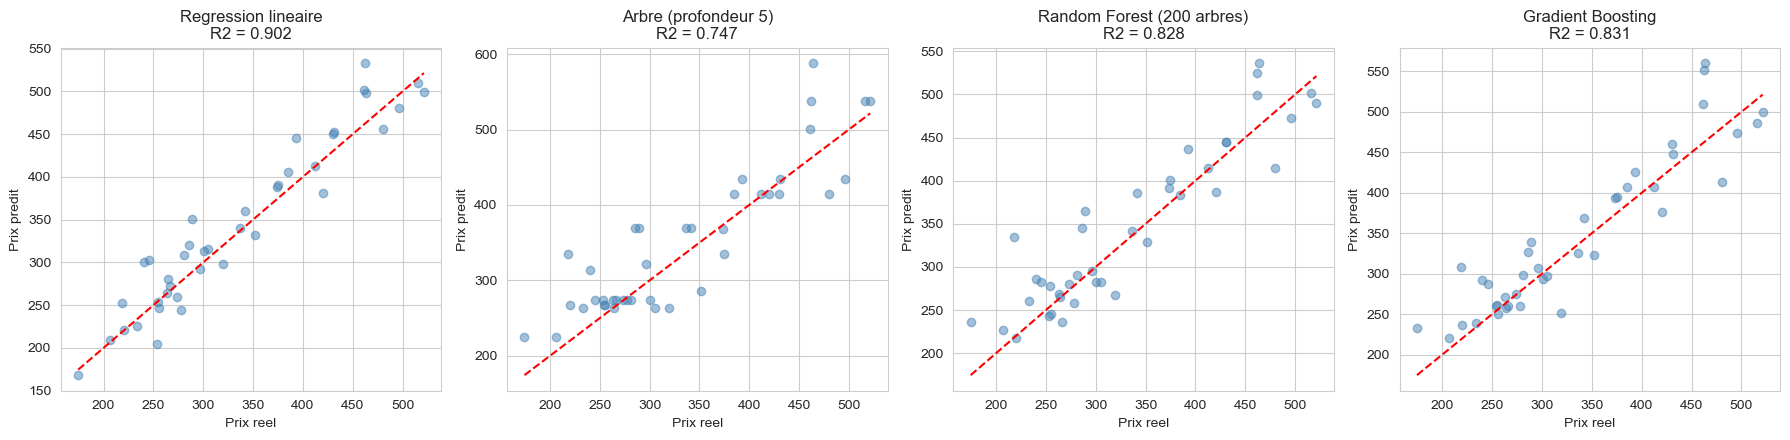

In [24]:
# Visualisation comparative : predit vs reel
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
lim = [y_test.min(), y_test.max()]
for ax, (nom, m) in zip(axes, modeles.items()):
    y_pred = m.predict(X_test)
    r2 = m.score(X_test, y_test)
    ax.scatter(y_test, y_pred, alpha=0.5, color='steelblue')
    ax.plot(lim, lim, 'r--', linewidth=1.5)
    ax.set_xlabel('Prix reel')
    ax.set_ylabel('Prix predit')
    ax.set_title(f'{nom}\nR2 = {r2:.3f}')
plt.tight_layout()
plt.show()

**Lecture.** Plus les points sont colles a la diagonale rouge, mieux le modele predit. La regression lineaire produit le nuage le plus serre autour de la diagonale. Les modeles a base d'arbres montrent des paliers visibles (les points se regroupent sur certaines valeurs), parce que les arbres predisent par zones.


## 9. Conclusion : la complexite n'est pas une garantie

**Resume des resultats :**

| Modele | R2 test | Verdict |
|---|---|---|
| Regression lineaire | ~0,90 | Le meilleur |
| Gradient Boosting | ~0,87 | Bon, mais en dessous |
| Random Forest | ~0,83 | Correct |
| Arbre de decision | ~0,63 | Le moins bon |

**Ce que cette demonstration nous apprend :**

1. **Un modele plus complexe n'est PAS forcement meilleur.** Sur ce dataset, plus le modele est complexe, plus il s'eloigne de la regression lineaire.
2. **Le choix du modele depend des donnees.** Quand la relation est lineaire, le modele lineaire est imbattable parce qu'il fait exactement ce qu'il faut. Les arbres approximent des droites par des escaliers : c'est forcement moins precis.
3. **Toujours commencer par la regression lineaire.** Elle sert de **ligne de base**. Un modele plus complexe ne se justifie que s'il bat reellement cette baseline sur le jeu de test.
4. **Quand les arbres brillent.** Les arbres et la foret aleatoire sont superieurs quand les relations sont **non-lineaires** (effets en U, en cloche, pics, seuils) ou quand il y a des **interactions** entre variables. Ce sera le sujet de la seance 9 sur l'apprentissage automatique.

**La regle d'or :** le bon modele n'est pas le plus complexe, c'est celui qui colle le mieux a la **structure des donnees**.
